<a href="https://colab.research.google.com/github/malakhaggage2020-afk/model-ML/blob/main/BOUNS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## 1. Dataset Exploration:

In [ ]:
df = pd.read_csv("house_data.csv")

In [ ]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 2. Exploratory Data Analysis (EDA):

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [ ]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [ ]:
df_copy = df.copy()

In [ ]:
df_copy.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [ ]:
df_copy.duplicated().sum()

np.int64(0)

In [ ]:
df_copy = df_copy.drop(columns= ['id'])

In [ ]:
df_copy.duplicated().sum()

np.int64(0)

In [ ]:
df_copy = df_copy.drop(columns= ['date'])

In [ ]:
df_copy.duplicated().sum()

np.int64(5)

In [ ]:
df_copy = df_copy.drop_duplicates()

In [ ]:
df_copy.duplicated().sum()

np.int64(0)

In [ ]:
df_copy.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
df_copy.waterfront.value_counts()

waterfront
0    21445
1      163
Name: count, dtype: int64

In [ ]:
df_copy.view.value_counts()

view
0    19485
2      963
3      509
1      332
4      319
Name: count, dtype: int64

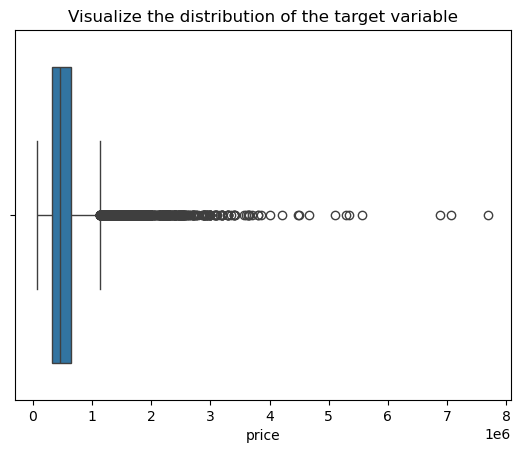

In [ ]:
sns.boxplot(x='price',data = df_copy)
plt.title("Visualize the distribution of the target variable")
plt.show()

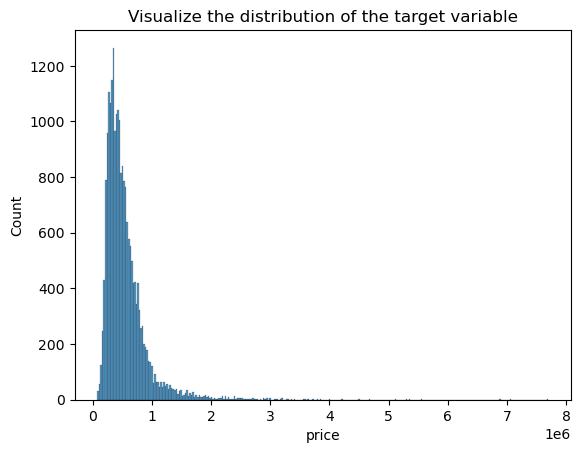

In [ ]:
sns.histplot(x='price',data = df_copy)
plt.title("Visualize the distribution of the target variable")
plt.show()

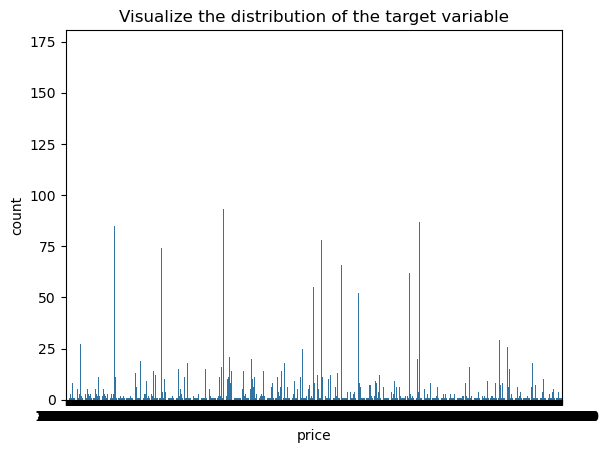

In [ ]:
sns.countplot(x='price',data = df_copy)
plt.title("Visualize the distribution of the target variable")
plt.show()

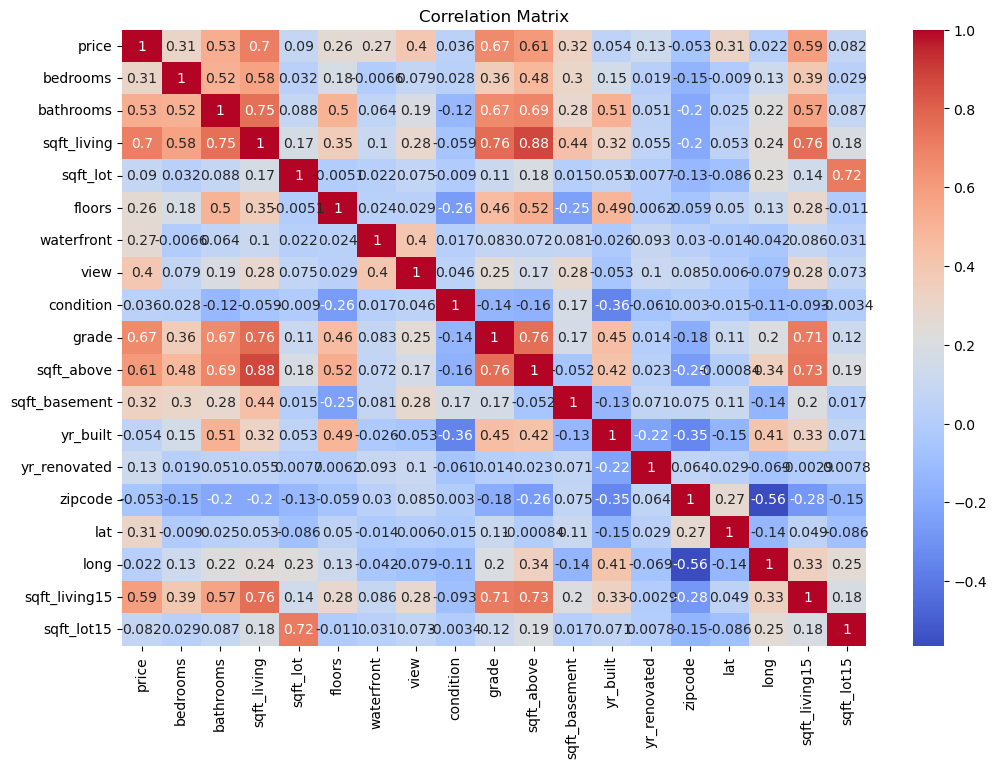

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap( df_copy.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

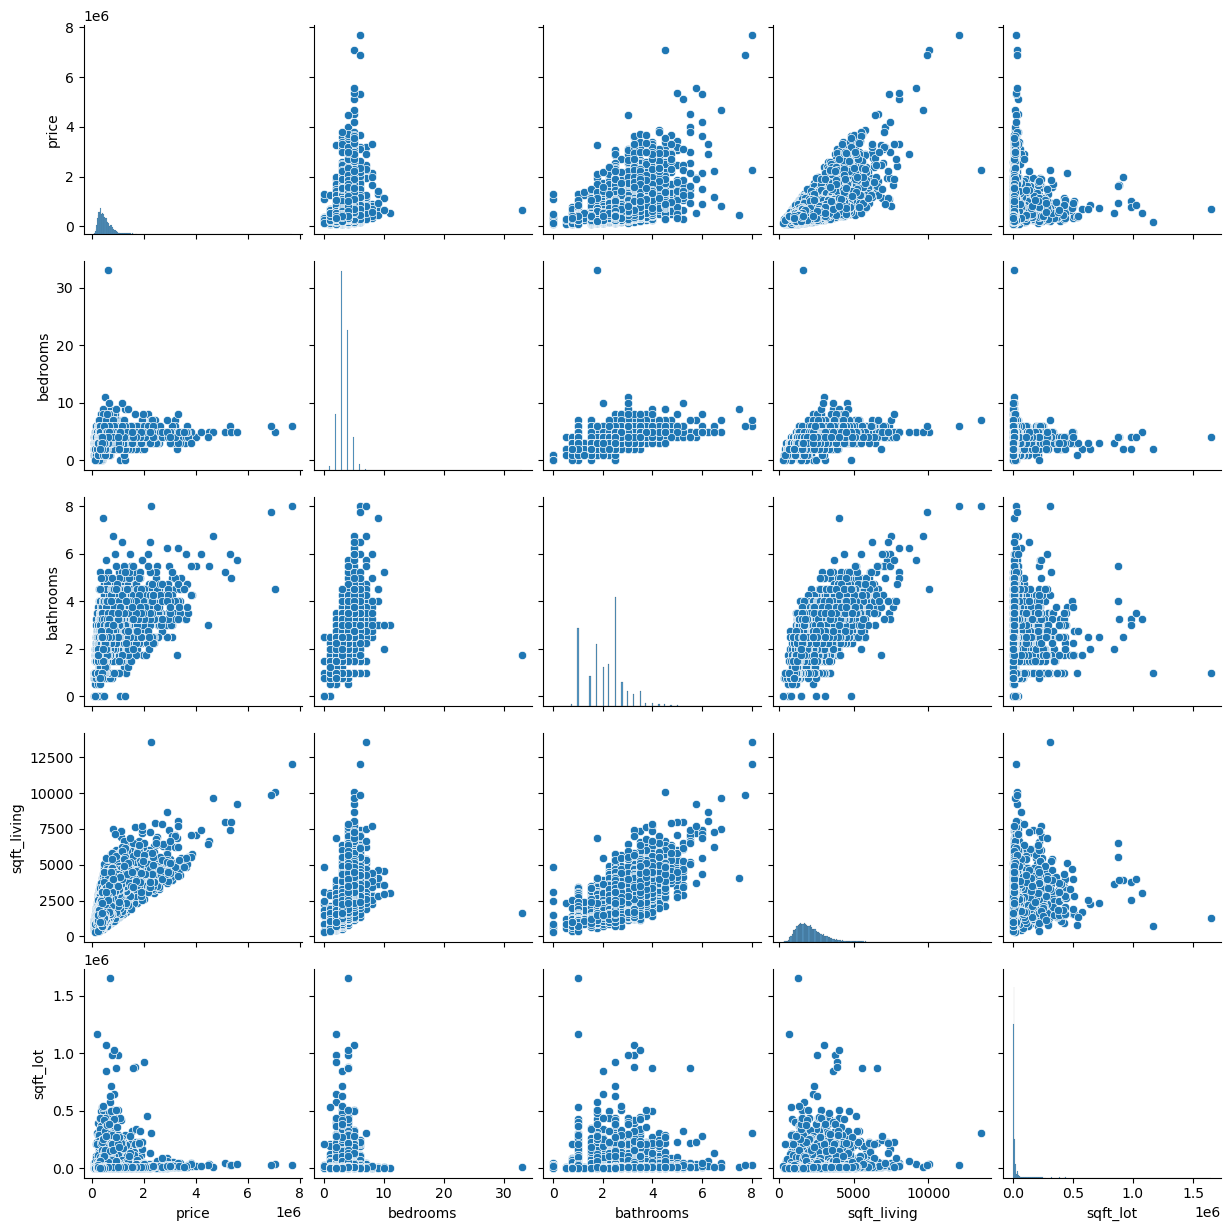

In [ ]:
sns.pairplot(df_copy[['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot']])
plt.show()

## 2. Train-Test Split:

In [ ]:
x = df_copy.drop(columns= ['price'])
y = df_copy['price']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
print(f'x_train = {x_train.shape}')
print(f'y_train = {y_train.shape}')
print(f'---'*10)
print(f'x_test = {x_test.shape}')
print(f'y_test = {y_test.shape}')

x_train = (17286, 18)
y_train = (17286,)
------------------------------
x_test = (4322, 18)
y_test = (4322,)


In [ ]:
x_train.describe()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,17286.000000,17286.000000,17286.000000,1.728600e+04,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000,17286.000000
mean,3.367002,2.111101,2073.133808,1.498866e+04,1.492595,0.007463,0.228277,3.405357,7.649196,1782.756624,290.377184,1970.896159,85.662675,98078.270913,47.560793,-122.214784,1982.963844,12684.829168
std,0.936198,0.770088,914.586284,4.030437e+04,0.540415,0.086066,0.756314,0.649009,1.167953,825.242189,442.491086,29.423648,404.516611,53.482429,0.138500,0.140654,682.297230,27191.469641
min,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.159300,-122.519000,399.000000,651.000000
25%,3.000000,1.500000,1420.000000,5.038500e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471525,-122.329000,1490.000000,5100.000000
50%,3.000000,2.250000,1910.000000,7.599000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.572800,-122.233000,1830.000000,7615.000000
75%,4.000000,2.500000,2540.000000,1.061250e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2200.000000,560.000000,1997.000000,0.000000,98118.000000,47.678600,-122.126000,2360.000000,10042.750000
max,33.000000,8.000000,13540.000000,1.164794e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## Handel nulls

In [ ]:
x_train.isnull().sum()

bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [ ]:
x_test.isnull().sum()

bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

## outliers

<Axes: xlabel='bedrooms'>

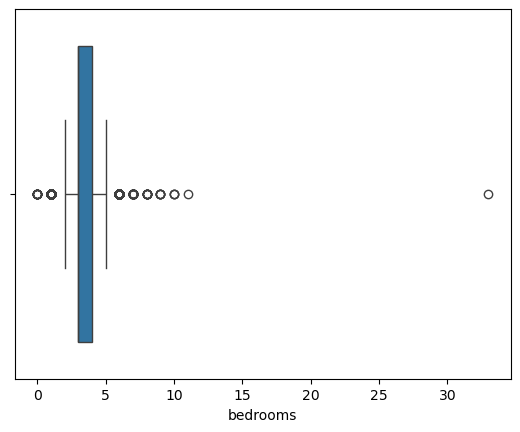

In [ ]:
sns.boxplot(x='bedrooms', data=x_train)

<Axes: xlabel='sqft_living'>

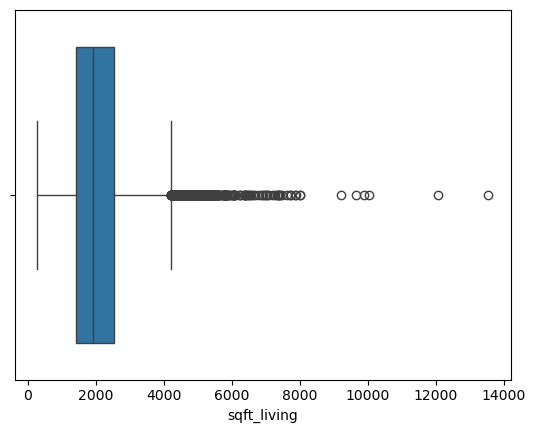

In [ ]:
sns.boxplot(x='sqft_living', data=x_train)

<Axes: xlabel='sqft_basement'>

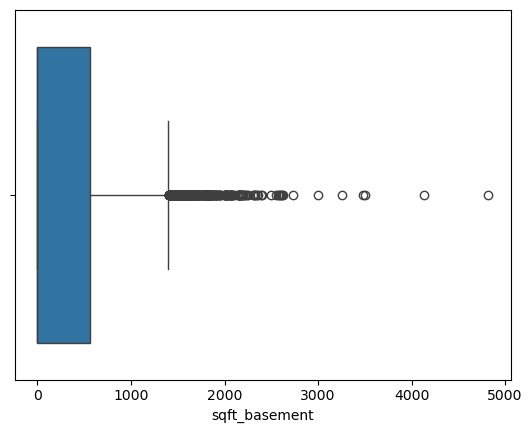

In [ ]:
sns.boxplot(x='sqft_basement', data=x_train)

<Axes: xlabel='sqft_lot15'>

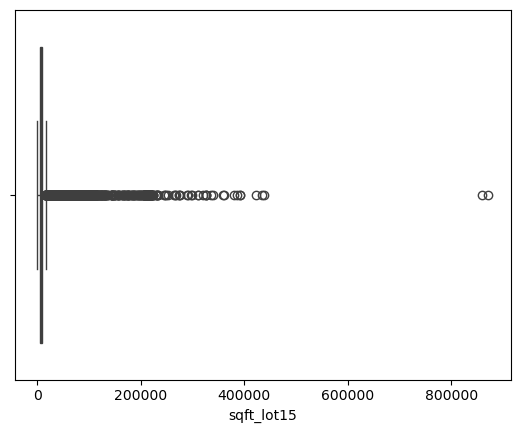

In [ ]:
sns.boxplot(x='sqft_lot15', data=x_train)

<Axes: xlabel='yr_renovated'>

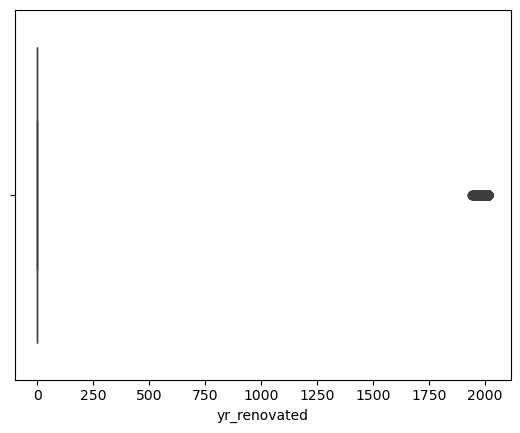

In [ ]:
sns.boxplot(x='yr_renovated', data=x_train)

In [ ]:
Q1 = x_train['sqft_basement'].quantile(0.25)
Q3 = x_train['sqft_basement'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask = (x_train['sqft_basement'] >= lower_bound) & (x_train['sqft_basement'] <= upper_bound)

#remove outliers from sqft_basement feature
x_train = x_train.loc[mask]
y_train = y_train.loc[mask]


<Axes: xlabel='sqft_basement'>

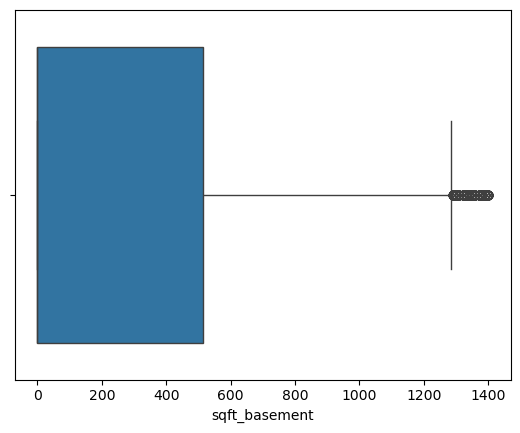

In [ ]:
sns.boxplot(x='sqft_basement', data=x_train)

In [ ]:
x_train.shape

(16900, 18)

In [ ]:
y_train.shape

(16900,)

## scaling

In [ ]:
from sklearn.preprocessing import RobustScaler

In [ ]:
scaler = RobustScaler()

In [ ]:
x_train[['sqft_living', 'sqft_lot','sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'lat', 'long','sqft_living15', 'sqft_lot15']] = scaler.fit_transform(x_train[['sqft_living', 'sqft_lot','sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'lat', 'long','sqft_living15', 'sqft_lot15']])
x_test[['sqft_living', 'sqft_lot','sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'lat', 'long','sqft_living15', 'sqft_lot15']] = scaler.transform(x_test[['sqft_living', 'sqft_lot','sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'lat', 'long','sqft_living15', 'sqft_lot15']])

In [ ]:
x_train.head()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
16969,5,5.25,2.962963,2.977415,2.0,0,0,3,12,3.514851,0.000000,0.673913,0,-0.776471,0.274571,0.090244,2.392857,3.081729
6250,2,1.50,-0.250000,-1.120114,2.0,0,0,3,9,-0.455446,1.048035,0.695652,0,0.870588,0.081345,-0.363415,-0.190476,-1.212208
13664,3,2.50,0.444444,0.073101,2.0,0,0,3,9,0.821782,0.000000,0.326087,0,-0.164706,-0.210639,0.309756,0.809524,0.135395
7243,4,3.00,0.842593,-0.059274,2.0,0,0,3,8,1.247525,0.000000,0.586957,0,-0.376471,-1.041746,1.080488,2.130952,0.058378
17291,4,2.50,0.351852,0.733868,1.0,0,0,3,8,0.000000,1.416788,-0.173913,0,-0.423529,0.652433,-0.031707,0.238095,0.687833


## Regression

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lr = LinearRegression()

In [ ]:
lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
lr.coef_

array([-2.56342585e+04,  3.98473306e+04,  8.27306542e+04,  5.31929455e+02,
        8.63753834e+03,  4.47004926e+05,  5.39862566e+04,  2.64281660e+04,
        9.68330556e+04,  8.00730194e+04,  1.64490188e+04, -1.15739091e+05,
        1.56930583e+01, -4.15478632e+04,  1.23641607e+05, -3.88295017e+04,
        2.24150139e+04, -1.16509232e+03])

In [ ]:
lr.intercept_

np.float64(-366755.8203318427)

In [ ]:
y_pred = lr.predict(x_test)

In [ ]:
y_pred

array([1022512.10583186,  527925.14317727,  301593.04010981, ...,
        293748.83329738,  468675.44803714,  197576.13535729],
      shape=(4322,))

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
mean_squared_error(y_test, y_pred)

42895538061.9838

In [ ]:
mean_absolute_error(y_test, y_pred)

124544.71845926129

In [ ]:
r2_score(y_test, y_pred)

0.69869614990602